In [9]:
%matplotlib inline
"""
Utility cell
"""


# Imports

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os
import re
from scipy import stats
#from statannot import add_stat_annotation
import scipy.optimize

sns.set()

# Utility functions

def list_csv_files(csv_folder_path):
    csv_files_list = []
    for root, directory, filenames in os.walk(csv_folder_path):
        for filename in filenames:
#            print(os.path.join(root, filename))
            csv_files_list.append(os.path.join(root, filename))
    return csv_files_list

def get_dataset_from_csv_folder(csv_folder_path):
    
    # Load the data
    csv_files_list = list_csv_files(csv_folder_path)
    data_frames_list = []
    for file in csv_files_list:
        # Iterate through the dataset of every file to catch only the "Entire organoids" for instance
        csv_df = pd.read_csv(file, sep=',', engine="python")
        csv_df['File_label'] = os.path.basename(file)
        data_frames_list.append(csv_df)
        # Add a label to the dataframe with the file name
    # Concatenate all the data frames in the filtered list
    df = pd.concat(data_frames_list)
   
    return df


In [10]:
"""
Loading the csv files
"""


# Folder to save produced graphs
graphs_folder = "../Graphs/"

# Loading dataset
csv_folder = "../csv/"

csv_files_list = list_csv_files(csv_folder)
print(len(csv_files_list))

csv_files_df = get_dataset_from_csv_folder(csv_folder)
print(len(csv_files_df))

# Dataset cleaning and labelling

print(csv_files_df.columns)
#print(csv_files_df.head())


# Iterate over each row and see whether we need to append it a "tip label"
tip_label_list = list(csv_files_df['Label'])
for index, label in enumerate(tip_label_list):
    # Remove the dataset header string
    tip_search = re.search('tip', label)
    if tip_search is None:
        # We are not looking at a tip
        tip_label_list[index] = "Not_tip"       
    else:
        tip_label_list[index] = "Tip"       
    
csv_files_df["Tip_label"] = tip_label_list


4
320
Index([' ', 'Label', 'Length', 'File_label'], dtype='str')


151


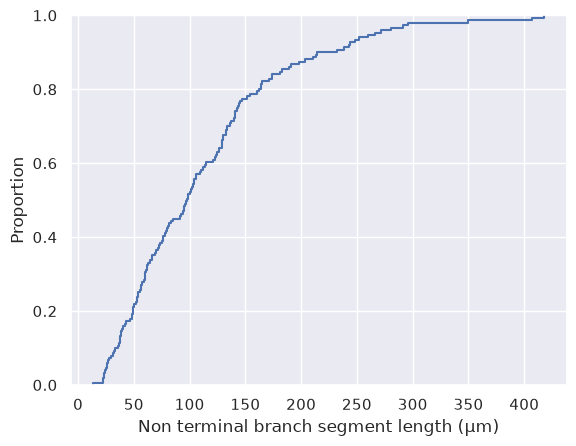

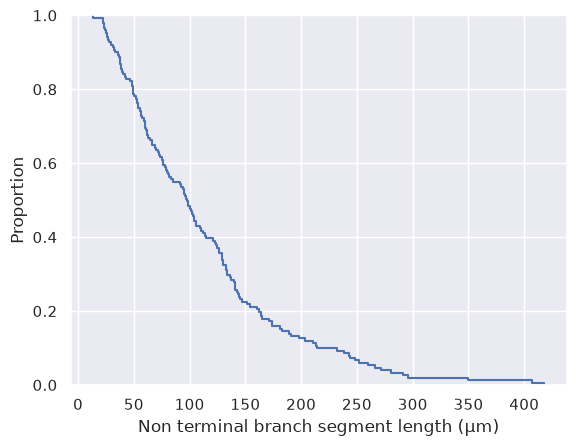

In [11]:
"""
For revisions: Plot the ECDF of non-tips branch length 
"""

csv_files_df_no_tip = csv_files_df.loc[csv_files_df['Tip_label'] == 'Not_tip']
print(len(csv_files_df_no_tip))

# Iterate over each row and see whether we need to append it a "tip label"
tip_label_list = list(csv_files_df['Label'])
for index, label in enumerate(tip_label_list):
    # Remove the dataset header string
    tip_search = re.search('tip', label)
    if tip_search is None:
        # We are not looking at a tip
        tip_label_list[index] = "Not_tip"       
    else:
        tip_label_list[index] = "Tip"       
    
csv_files_df["Tip_label"] = tip_label_list


csv_files_df_no_tip.to_csv(os.path.join(graphs_folder,"non_terminal_branch_segment_length")+'.csv')


plt.figure()
g = sns.ecdfplot(x='Length', data=csv_files_df_no_tip)
plt.xlabel("Non terminal branch segment length (µm)")
#plt.savefig(os.path.join(graphs_folder,"ECDF_non_terminal_branch_segment_length")+'.svg')
#plt.savefig(os.path.join(graphs_folder,"ECDF_non_terminal_branch_segment_length")+'.png')
plt.show()


plt.figure()
g = sns.ecdfplot(x='Length', data=csv_files_df_no_tip, complementary=True)
plt.xlabel("Non terminal branch segment length (µm)")
#plt.savefig(os.path.join(graphs_folder,"Complementary_ECDF_non_terminal_branch_segment_length")+'.svg')
#plt.savefig(os.path.join(graphs_folder,"Complementary_ECDF_non_terminal_branch_segment_length")+'.png')
plt.show()

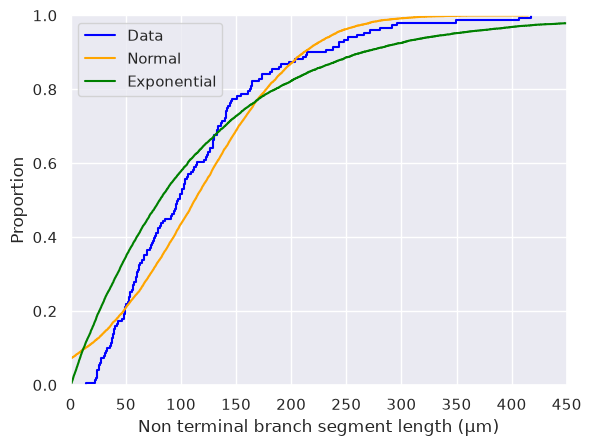

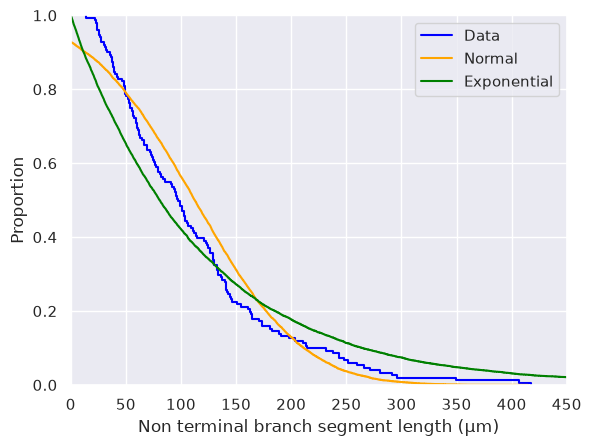

In [12]:
"""
For revisions: Plot the ECDF of non-tips branch length along with a simulated normal and exponential distribution, without any fit
"""
np.random.seed(42)
mean_branch_length = np.mean(csv_files_df_no_tip['Length'])
std_mean_branch_length = np.std(csv_files_df_no_tip['Length'])

normal_dist_branch_length = np.random.normal(mean_branch_length, std_mean_branch_length, size=10000)
exp_dist_branch_length = np.random.exponential(mean_branch_length, size=10000)

plt.figure()
g = sns.ecdfplot(x='Length', data=csv_files_df_no_tip, color='blue', label='Data')
sns.ecdfplot(normal_dist_branch_length, color='orange', label='Normal')
sns.ecdfplot(exp_dist_branch_length, color='green', label='Exponential')
plt.xlim(0, 450)
plt.xlabel("Non terminal branch segment length (µm)")
plt.legend()
#plt.savefig(os.path.join(graphs_folder,"ECDF_and_simulated_distributions_non_terminal_branch_segment_length")+'.svg')
#plt.savefig(os.path.join(graphs_folder,"ECDF_and_simulated_distributions_non_terminal_branch_segment_length")+'.png')
plt.show()


plt.figure()
g = sns.ecdfplot(x='Length', data=csv_files_df_no_tip, color='blue', label='Data', complementary=True)
sns.ecdfplot(normal_dist_branch_length, color='orange', label='Normal', complementary=True)
sns.ecdfplot(exp_dist_branch_length, color='green', label='Exponential', complementary=True)
plt.xlim(0, 450)
plt.xlabel("Non terminal branch segment length (µm)")
plt.legend()
#plt.savefig(os.path.join(graphs_folder,"cECDF_and_simulated_distributions_non_terminal_branch_segment_length")+'.svg')
#plt.savefig(os.path.join(graphs_folder,"cECDF_and_simulated_distributions_non_terminal_branch_segment_length")+'.png')
plt.show()

R² = 0.9915047515886287


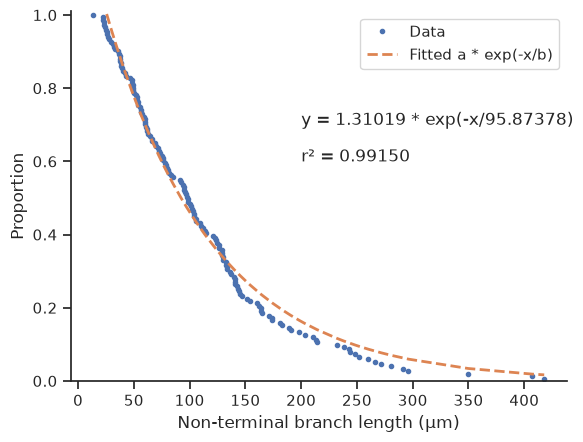

Y = 1.3101872012581486 * e^(- * x) / 95.8737840708552


In [13]:
"""
Determining an exponential fit for the non-terminal branch length distribution, fitting for x > 15
"""

def monoExp(x, a, b):
    return a * np.exp(-x/b)

# Get the x and y data for the fit 
x_sorted = np.sort(csv_files_df_no_tip['Length'])
n_full = len(x_sorted)
y_full = np.arange(1, n_full+1)/n_full
y_full_reversed = y_full[::-1]


# Select only the branches above 15 microns for the fit
x_cutoff = x_sorted[x_sorted>15]
n_cutoff = len(x_cutoff)
y_cutoff = np.arange(1, n_cutoff+1)/n_cutoff

# For the complementary ECDF, we reverse the y array to go from 1 to 1/n
y_cutoff_reversed = y_cutoff[::-1]

# STARTING VALUES FOR THE FIT OPTIMIZATION
# We assume that the branches cannot be smaller that 15 microns 
# Need to start with an assumption of 1.1 for "a"; at 1.0, the fit doesn't work
# No assumption on "b" initially
p0 = (1.1, 1)

# Fitting
params, cv = scipy.optimize.curve_fit(monoExp, x_cutoff, y_cutoff_reversed, p0)
# Extract the fitting parameters
a, b = params


# Compute the r^2 to check the fit quality
squaredDiffs = np.square(y_cutoff_reversed - monoExp(x_cutoff, a, b))
squaredDiffsFromMean = np.square(y_cutoff_reversed - np.mean(y_cutoff_reversed))
rSquared = 1 - np.sum(squaredDiffs) / np.sum(squaredDiffsFromMean)
print(f"R² = {rSquared}")




with sns.axes_style('ticks'):
    plt.plot(x_sorted, y_full_reversed, '.', label="Data")
    plt.plot(x_cutoff, monoExp(x_cutoff, a, b), '--', linewidth=2,label="Fitted a * exp(-x/b)")
    plt.xlabel("Non-terminal branch length (µm)")
    plt.ylabel("Proportion")
    plt.legend()
    sns.despine()
    plt.ylim(0,1.01)
    plt.text(200, 0.7, 'y = {:.5f} * exp(-x/{:.5f})'.format(a,b), size=12)
    plt.text(200, 0.6, 'r² = {:.5f}'.format(rSquared, size=12))
#    plt.savefig(os.path.join(graphs_folder, "cECDF_and_exp_fit_non_terminal_xsup15") + '_revisions.png', bbox_inches='tight') 
#    plt.savefig(os.path.join(graphs_folder, "cECDF_and_exp_fit_non_terminal_xsup15") + '_revisions.svg', bbox_inches='tight') 
    plt.show()

print(f"Y = {a} * e^(- * x) / {b}")

R² = 0.9904350244848463
Y = 1.2907419149596995 * e^(- * x) / 96.7668505336066


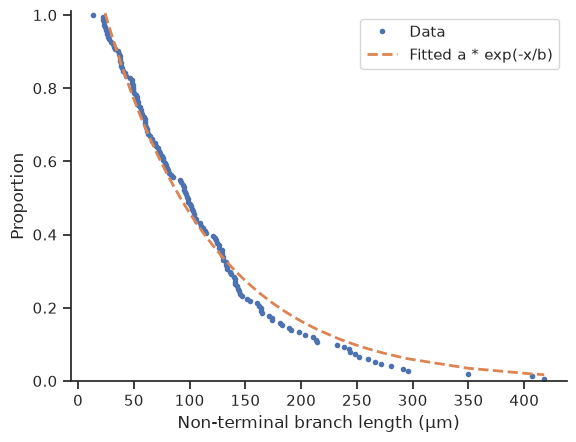

In [14]:
"""
For checking purposes, we can also determine an exponential fit for the non-terminal branch length distribution,
without restrictions on x
"""


# Folder to save produced graphs
graphs_folder = "../Graphs/"



# Define a standard decaying exponential
def monoExp(x, a, b):
    return a * np.exp(-x/b)

# Get the x and y data for the fit 
n = len(csv_files_df_no_tip)
x_sorted = np.sort(csv_files_df_no_tip['Length'])
y = np.arange(1, n+1)/n

# For the complementary ECDF, we reverse the y array to go from 1 to 1/n
y_reversed = y[::-1]

# STARTING VALUES FOR THE FIT OPTIMIZATION
# We assume that the branches cannot be smaller that 15 microns (so constraint on the "a"). 
# No assumption on "b" initially
p0 = (1, 1)

# Fitting
params, cv = scipy.optimize.curve_fit(monoExp, x_sorted, y_reversed, p0)
# Extract the fitting parameters
a, b = params


# Compute the r^2 to check the fit quality
squaredDiffs = np.square(y_reversed - monoExp(x_sorted, a, b))
squaredDiffsFromMean = np.square(y_reversed - np.mean(y_reversed))
rSquared = 1 - np.sum(squaredDiffs) / np.sum(squaredDiffsFromMean)
print(f"R² = {rSquared}")




with sns.axes_style('ticks'):
    plt.plot(x_sorted, y_reversed, '.', label="Data")
    plt.plot(x_sorted, monoExp(x_sorted, a, b), '--', linewidth=2,label="Fitted a * exp(-x/b)")
    plt.xlabel("Non-terminal branch length (µm)")
    plt.ylabel("Proportion")
    plt.legend()
    sns.despine()
    plt.ylim(0,1.01)
#    plt.savefig(os.path.join(graphs_folder, "cECDF_and_exp_fit_non_terminal") + '_revisions.png', bbox_inches='tight') 
#    plt.savefig(os.path.join(graphs_folder, "cECDF_and_exp_fit_non_terminal") + '_revisions.svg', bbox_inches='tight') 

print(f"Y = {a} * e^(- * x) / {b}")